# Seq2Seq 시퀀스투시퀀스 실습

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/slides/v2/ml1/week12/seq2seq/lab/seq2seq.ipynb)

인코더가 문장을 벡터 하나로 읽고, 디코더가 그 벡터에서 한 단어씩 쓴다.

- **파트 1**: 데이터 만들기: 영어 숫자 말 → 숫자 (`nine hundred four` → `904`)
- **파트 2**: GRU 인코더-디코더 학습 · 번역 · 틀린 예
- **파트 3**: 숫자열 베끼기: 길이별 정답률, 입력 그대로 vs 거꾸로

`None` 으로 비워 둔 `TODO` 줄을 채우고 셀을 차례로 실행하세요.

In [ ]:
import random
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn

## 파트 1. 영어 숫자 말

0 ~ 999 를 영어 단어로. 입력은 단어 1 ~ 4개, 출력은 글자 1 ~ 3개 + 끝 표시 `</s>`. 길이가 서로 다르다.

In [ ]:
ONES = "zero one two three four five six seven eight nine".split()
TEENS = "ten eleven twelve thirteen fourteen fifteen sixteen seventeen eighteen nineteen".split()
TENS = "_ _ twenty thirty forty fifty sixty seventy eighty ninety".split()

def words(n):
    if n < 10:
        return [ONES[n]]
    if n < 20:
        return [TEENS[n - 10]]
    if n < 100:
        return [TENS[n // 10]] + ([ONES[n % 10]] if n % 10 else [])
    return None  # TODO: hundreds, then the rest (if any)

for n in [7, 13, 40, 904, 696]:
    print(n, "->", " ".join(words(n)))

**예상 결과**

```
7 -> seven
13 -> thirteen
40 -> forty
904 -> nine hundred four
696 -> six hundred ninety six
```

In [ ]:
SRC = ["<pad>"] + sorted(set(ONES + TEENS + TENS[2:] + ["hundred"]))    # input words
TGT = ["<pad>", "<s>", "</s>"] + list("0123456789")                       # output characters
src_id = {w: i for i, w in enumerate(SRC)}
tgt_id = {c: i for i, c in enumerate(TGT)}

def pad(seqs):
    L = max(len(s) for s in seqs)
    return torch.tensor([s + [0] * (L - len(s)) for s in seqs])

def make_batch(nums):
    x = pad([[src_id[w] for w in words(n)] for n in nums])
    y = [[tgt_id[c] for c in str(n)] + [tgt_id["</s>"]] for n in nums]
    y_in = pad([[tgt_id["<s>"]] + s[:-1] for s in y])                     # decoder input: shifted right
    return x, y_in, pad(y)

random.seed(0)
nums = list(range(1000)); random.shuffle(nums)
train_nums, test_nums = nums[:800], nums[800:]
x, y_in, y_out = make_batch([904, 70])
print("x    :", x.tolist()); print("y_in :", y_in.tolist()); print("y_out:", y_out.tolist())

**예상 결과**

```
x    : [[12, 11, 9], [18, 0, 0]]
y_in : [[1, 12, 3, 7], [1, 10, 3, 0]]
y_out: [[12, 3, 7, 2], [10, 3, 2, 0]]
```

## 파트 2. 인코더-디코더

인코더 GRU 의 마지막 메모 = 벡터 $\mathbf{v}$ → 디코더 GRU 의 첫 메모. 배울 때는 정답 앞 단어를 넣고 (teacher forcing), 쓸 때는 자기가 쓴 글자를 넣는다 (greedy).

In [ ]:
class Seq2Seq(nn.Module):
    def __init__(self, n_src, n_tgt, hidden=128):
        super().__init__()
        self.src_emb, self.tgt_emb = nn.Embedding(n_src, hidden), nn.Embedding(n_tgt, hidden)
        self.encoder = nn.GRU(hidden, hidden, batch_first=True)
        self.decoder = nn.GRU(hidden, hidden, batch_first=True)
        self.out = nn.Linear(hidden, n_tgt)

    def forward(self, x, y_in):
        _, v = self.encoder(self.src_emb(x))                            # v: the one vector
        o = None  # TODO: run the decoder starting from v
        return self.out(o)

    @torch.no_grad()
    def greedy(self, x, n_steps, bos=1):
        _, s = self.encoder(self.src_emb(x))
        t = torch.full((x.shape[0], 1), bos); outs = []
        for _ in range(n_steps):
            o, s = self.decoder(self.tgt_emb(t), s)
            t = None  # TODO: the most likely next token
            outs.append(t)
        return torch.cat(outs, 1)

def train_numbers(train_nums, steps=3000):
    torch.manual_seed(0); random.seed(0)
    model = Seq2Seq(len(SRC), len(TGT)); opt = torch.optim.Adam(model.parameters(), 3e-3); losses = []
    for step in range(steps):
        x, y_in, y_out = make_batch(random.sample(train_nums, 64))
        logits = model(x, y_in)
        loss = nn.functional.cross_entropy(logits.reshape(-1, len(TGT)), y_out.reshape(-1), ignore_index=0)
        opt.zero_grad(); loss.backward(); opt.step(); losses.append(loss.item())
    return model, losses

model, losses = train_numbers(train_nums)
plt.plot(losses); plt.yscale("log"); plt.xlabel("step"); plt.ylabel("loss"); plt.show()

**예상 결과**

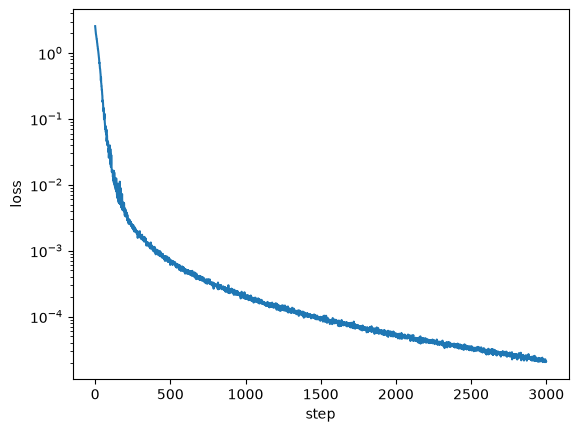

In [ ]:
def translate(model, nums):
    x, _, _ = make_batch(nums)
    rows = model.greedy(x, 4).tolist()
    return ["".join(TGT[t] for t in row).split("</s>")[0] for row in rows]

pred = translate(model, test_nums)
correct = [p == str(n) for p, n in zip(pred, test_nums)]
print(f"test accuracy: {sum(correct)} / {len(test_nums)}")
for n, p, ok in list(zip(test_nums, pred, correct))[:5]:
    print(f"{' '.join(words(n)):28s} -> {p}")
print("wrong:")
for n, p, ok in zip(test_nums, pred, correct):
    if not ok:
        print(f"  {' '.join(words(n)):28s} -> {p}   (answer {n})")

**예상 결과**

```
test accuracy: 199 / 200
six hundred ninety six       -> 696
nine hundred sixty five      -> 965
five hundred forty seven     -> 547
six hundred forty nine       -> 649
five hundred eighty seven    -> 587
wrong:
  seventy                      -> 77   (answer 70)
```

## 파트 3. 숫자열 베끼기: 벡터 하나는 비좁다

가장 쉬운 번역: 숫자열을 그대로 쓰기. 벡터 32칸 GRU 로 길이 5 ~ 30 을 섞어 배운 뒤, 길이별로 숫자를 몇 % 맞히는지 잰다. 입력을 거꾸로 넣으면?

In [ ]:
def train_copy(reverse, hidden=32, steps=4000):
    torch.manual_seed(0); g = torch.Generator().manual_seed(0)
    model = Seq2Seq(12, 13, hidden)              # input: 0 pad, 1..10 digits / output: 0 pad, 1 <s>, 2 </s>, 3..12 digits
    opt = torch.optim.Adam(model.parameters(), 3e-3)
    for step in range(steps):
        n = int(torch.randint(5, 31, (1,), generator=g))
        d = torch.randint(0, 10, (64, n), generator=g)
        x = None  # TODO: input digits (+1), reversed if asked
        y = d + 3
        y_in = torch.cat([torch.ones(64, 1, dtype=torch.long), y], 1)[:, :-1]
        loss = nn.functional.cross_entropy(model(x, y_in).reshape(-1, 13), y.reshape(-1))
        opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
    return model

def copy_accuracy(model, reverse, lengths):
    acc = []
    for n in lengths:
        d = torch.randint(0, 10, (500, n), generator=torch.Generator().manual_seed(n))
        x = (d.flip(1) if reverse else d) + 1
        pred = model.greedy(x, n) - 3
        acc.append((pred == d).float().mean().item() * 100)
    return acc

lengths = [5, 10, 15, 20, 25, 30]
for reverse in [False, True]:
    acc = copy_accuracy(train_copy(reverse), reverse, lengths)
    print("reversed" if reverse else "as is   ", [round(a) for a in acc])
    plt.plot(lengths, acc, "o-", label="reversed" if reverse else "as is")
plt.axhline(10, ls=":", color="gray"); plt.xlabel("sequence length"); plt.ylabel("digits correct (%)"); plt.legend(); plt.show()

**예상 결과**

```
as is    [93, 60, 42, 32, 27, 24]
reversed [99, 73, 49, 38, 33, 28]
```

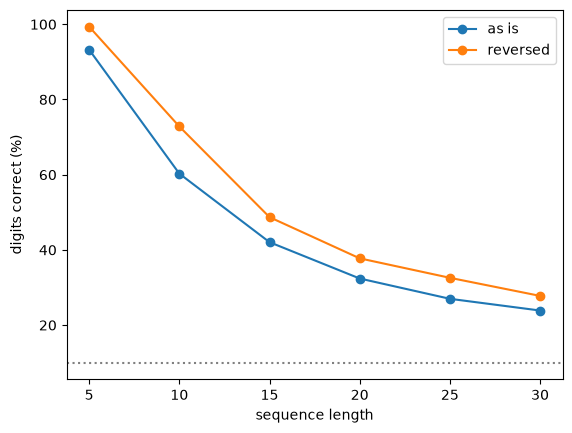

**확인 질문**
1. 파트 2 에서 틀린 예는 어떤 공통점이 있나? 왜 그런 말이 어려울까?
2. 파트 2 의 `greedy` 에서 4글자까지만 쓰게 한 이유는? 이 값을 빼면 어떻게 될까?
3. 파트 3 에서 `hidden` 을 32 → 128 로 늘리면 길이 30 정답률은? 그래도 끝없이 긴 문장은 왜 어려울까?
4. (도전) 디코더가 매 글자마다 인코더의 **모든** 칸을 볼 수 있다면 파트 3 은 어떻게 될까? (다음 시간: 어텐션)